# 8. Reproducing a published estimate: FeMoco

FeMoco, the iron–molybdenum cofactor of nitrogenase, is the standard benchmark for chemistry on a fault-tolerant quantum computer. Lee et al. [[arXiv:2011.03494](https://arxiv.org/abs/2011.03494), Table III] give $1.0\times10^{10}$ Toffolis on 3725 logical qubits for its 54-orbital active space by double factorization. Can that number be rebuilt from the integrals, line by line, and which lines dominate?

In [1]:
import matplotlib.pyplot as plt
from openfermion.resource_estimates import df as of_df

import qcost
from qcost.factorization import (
    df_lambda,
    df_logical_qubits,
    df_walk_toffolis,
    df_walk_toffolis_c39,
    double_factorize,
    reiher_femoco,
)
from qcost.walk import walk_calls

## The integrals, factorized

The active space of Reiher et al. [[arXiv:1605.03590](https://arxiv.org/abs/1605.03590)]: 54 electrons in 54 spatial orbitals, $N = 108$ spin orbitals. The integrals ship with OpenFermion (68 MB). Factorize them with the code of notebook 05 at Lee et al.'s threshold, $1.25\times10^{-3}$, chosen so that the CCSD(T) energy moves by less than 0.6 mHa [their Sec. III A]:

In [2]:
h1, eri, ecore = reiher_femoco()
factors, L, LXi = double_factorize(eri, thresh=0.00125)
lam = df_lambda(h1, eri, factors)
print(f"orbitals {h1.shape[0]};  L = {L},  eigenvectors L*Xi = {LXi}")
print(f"lambda = {lam['total']:.1f} Ha  (one-body {lam['one-body']:.1f} + two-body {lam['two-body']:.1f})")
print("Lee et al., Table XIII: L = 360, L*Xi = 13031, lambda = 294.8, one-body 38.6")

orbitals 54;  L = 360,  eigenvectors L*Xi = 13031
lambda = 294.8 Ha  (one-body 38.6 + two-body 256.3)
Lee et al., Table XIII: L = 360, L*Xi = 13031, lambda = 294.8, one-body 38.6


All four numbers match.

## One walk step, line by line

Lee et al., App. C, list the circuit in ten steps. With $\aleph = 10$ bits per alias-sampling keep value and $\beth = 16$ bits per rotation angle [Table III caption]:

In [3]:
step = df_walk_toffolis(N=108, L=L, LXi=LXi, aleph=10, beth=16)
for k, v in step.items():
    print(f"{k:40} {v:6d}  {100 * v / step['total']:5.1f}%")

1 prepare l (uniform, x2)                    64    0.3%
1 prepare l (QROM + inverse)                187    0.9%
1 prepare l (compare, swap, x2)              38    0.2%
2 data for second preparation               214    1.0%
3 prepare m (uniform, x4)                   200    0.9%
3 prepare m (offsets, x4)                    52    0.2%
3 prepare m (QROMs + inverses)             2394   11.0%
3 prepare m (compare, swap, x4)              64    0.3%
4 rotations (offsets)                        52    0.2%
4 rotations (angle QROMs + inverses)      12175   56.0%
4 rotations (spin swaps)                    216    1.0%
4 rotations (Givens, phase gradient)       6048   27.8%
4 controlled Z                                3    0.0%
6 reflection on m                            18    0.1%
9 reflection for the walk                    26    0.1%
10 control qubits                             2    0.0%
total                                     21753  100.0%


Two lines are 84% of the step:

* **Looking up the rotation angles** (56%): for each of the $L\Xi + N/2$ eigenvectors, the $N/2$ Givens angles of its orbital rotation, $\beth$ bits each, a table of 13 085 words of 864 bits (the extra $N/2$ words are for the one-body term), and a second table of 13 031 words, without the one-body term. Each is a select/swap lookup of notebook 03 with its measurement-based undo [steps 4(b) and 4(g)].
* **Applying the rotations** (28%): $4N$ rotations by adding into a phase gradient, $\beth - 2$ Toffolis each (notebook 02).

Everything else, the two alias samplings (notebook 04), the reflections, the offsets, is 16%.

## The whole run

In [4]:
calls = walk_calls(294.8, 0.001)       # 1 mHa for phase estimation, 0.6 mHa left for the factorization
total = calls * step["total"]
qubits = df_logical_qubits(108, L, LXi, calls, aleph=10, beth=16)
print(f"walk calls {calls:,}  x  {step['total']:,} Toffolis  =  {total:,} Toffolis")
print(f"logical qubits {qubits['total']:,}")
print("Lee et al., Table III: 1.0e10 Toffolis, 3725 logical qubits")
first = of_df.compute_cost(108, 294.8, 0.001, 360, 13031, 10, 16, 20000)[0]
print("OpenFermion:", of_df.compute_cost(108, 294.8, 0.001, 360, 13031, 10, 16, first), "(per step, total, qubits)")

walk calls 463,071  x  21,753 Toffolis  =  10,073,183,463 Toffolis
logical qubits 3,725
Lee et al., Table III: 1.0e10 Toffolis, 3725 logical qubits
OpenFermion: (21753, 10073183463, 3725) (per step, total, qubits)


Exact, to the last Toffoli and the last qubit. The qubits, register by register:

In [5]:
for k, v in qubits.items():
    print(f"{k:38} {v:6d}")

phase estimation control                   37
system (spin orbitals)                    108
first index l, rotated qubit, flag         11
QROM output, superposition, flag           30
data for second preparation                28
second index m, rotated qubit, flag         8
second QROM output                         18
second superposition, flag                 11
rotation angles (k_r words)              3456
phase gradient                             16
spin control, T state                       2
total                                    3725


The rotation angles of a select/swap block, $k_r N\beth/2$ with $k_r = 4$, take 3456 of the 3725 qubits, over 90%: the space the lookup trades for its Toffoli savings (notebook 03). The system itself is 108.

## The closed form

Lee et al. also sum their step list into one expression, Eq. C39. Evaluated with the same choices it comes to

In [6]:
c39 = df_walk_toffolis_c39(108, L, LXi, aleph=10, beth=16)
print(f"Eq. C39: {c39}, step list: {step['total']}, difference {c39 - step['total']} = aleph - 1")

Eq. C39: 21762, step list: 21753, difference 9 = aleph - 1


Summing the step list term by term gives $8\aleph - 42$ for the parts that are not lookups; Eq. C39 has $3\aleph_1 + 6\aleph_2 - 43 = 9\aleph - 43$ when $\aleph_1 = \aleph_2 = \aleph$. The published totals follow the step list. A difference of 9 in 21 753 changes nothing, but it is the kind of thing a reproduction finds and a reading does not.

The second Hamiltonian in Lee et al., the 76-orbital active space of Li et al. [[arXiv:1809.10307](https://arxiv.org/abs/1809.10307)], is not shipped with OpenFermion. From the published factorization ($L = 394$, $L\Xi = 20\,115$, $\lambda = 1171.2$, $\beth = 20$) the step list gives their number exactly when the first rotation uses 6 bits, as OpenFermion chooses:

In [7]:
li = df_walk_toffolis(152, 394, 20115, aleph=10, beth=20, b_r_first=6)["total"]
li_calls = walk_calls(1171.2, 0.001)
li_qubits = df_logical_qubits(152, 394, 20115, li_calls, beth=20)["total"]
print(f"Li et al.: {li:,} per step x {li_calls:,} calls = {li * li_calls:.2e} Toffolis; {li_qubits} logical qubits")
print("Lee et al., Table III: 6.4e10 Toffolis, 6404 logical qubits (OpenFermion: 6405)")

Li et al.: 35,011 per step x 1,839,717 calls = 6.44e+10 Toffolis; 6405 logical qubits
Lee et al., Table III: 6.4e10 Toffolis, 6404 logical qubits (OpenFermion: 6405)


## The threshold as a dial

Raise the threshold and fewer eigenvectors survive: fewer angles to load, slightly smaller $\lambda$, a less accurate Hamiltonian. Live (a few seconds):

threshold 1.0e-04: L = 581, L*Xi = 25054, lambda =  296.7, Toffolis 1.35e+10
threshold 3.0e-04: L = 488, L*Xi = 19780, lambda =  296.4, Toffolis 1.20e+10
threshold 1.3e-03: L = 360, L*Xi = 13031, lambda =  294.8, Toffolis 1.01e+10
threshold 5.0e-03: L = 242, L*Xi =  7181, lambda =  289.5, Toffolis 8.20e+09
threshold 1.0e-02: L = 195, L*Xi =  4700, lambda =  283.4, Toffolis 6.76e+09


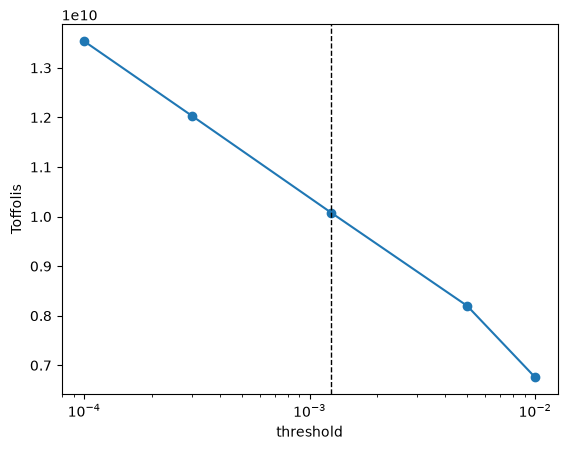

In [8]:
threshs = [1e-4, 3e-4, 1.25e-3, 5e-3, 1e-2]
rows = []
for t in threshs:
    f, Lt, LXit = double_factorize(eri, t)
    lt = df_lambda(h1, eri, f)["total"]
    rows.append((t, Lt, LXit, lt, df_walk_toffolis(108, Lt, LXit)["total"] * walk_calls(lt, 0.001)))
for t, Lt, LXit, lt, tof in rows:
    print(f"threshold {t:7.1e}: L = {Lt:3d}, L*Xi = {LXit:5d}, lambda = {lt:6.1f}, Toffolis {tof:.2e}")
plt.semilogx([r[0] for r in rows], [r[4] for r in rows], "o-")
plt.axvline(1.25e-3, color="k", lw=1, ls="--")
plt.xlabel("threshold")
plt.ylabel("Toffolis");

Two orders of magnitude in the threshold change the cost by a factor of two: $\lambda$ barely moves, and the lookups grow only like $\sqrt{L\Xi}$. The threshold is set by accuracy, not by cost.

## In context

* von Burg et al. [[arXiv:2007.14460](https://arxiv.org/abs/2007.14460), Table II], who introduced this double-factorized walk for FeMoco, give $2.3\times10^{10}$ Toffolis on 3600 qubits; Lee et al. recost it with the step list above and get $1.0\times10^{10}$.
* Tensor hypercontraction, the subject of Lee et al., brings it to $5.3\times10^9$ Toffolis on 2142 qubits [Table III].
* Physical cost, with the model of notebook 06:

In [9]:
qcost.show(qcost.surface_code.footprint(qubits["total"], total, factories=4, budget=0.1))

distance                                                   31
physical qubits                                    11,997,760
data qubits                                        11,444,224
factory qubits                                        553,536
seconds per Toffoli                                  4.26e-05
hours                                                  119.27


About five days and twelve million physical qubits at $p = 10^{-3}$, with four factories.

## Exercises

1. Which single change to the step list would cut the cost most: halving $\beth$, halving $L\Xi$, or halving $\lambda$? Estimate each with `df_walk_toffolis` and `walk_calls`, then think about which is physically possible.
2. Replace the select/swap lookups by plain QROMs ($k = 1$). How many more Toffolis per step, and how many fewer qubits?
3. Spend the whole 1.6 mHa on phase estimation (a perfect factorization). How much cheaper is the run? Is it worth the factorization error?